In [72]:
# Feature engineering and text processing

# Required libraries: pandas, numpy, matplotlib, scipy, and scikit-learn.
# The notebook uses only the local data file; it downloads nothing.

from pathlib import Path
import os
import re
import pandas as pd

# Works from the repository root or from meeting_03.
candidates = [Path("meeting_slides/meeting_03/federalist.csv"), Path("federalist.csv")]
DATA = next((p for p in candidates if p.exists()), None)
if DATA is None:
    raise FileNotFoundError("Could not find federalist.csv.")

federalist = pd.read_csv(DATA)
print(f"Loaded {len(federalist)} essays from {DATA}")
print(federalist["author"].value_counts())


Loaded 85 essays from federalist.csv
author
HAMILTON                51
MADISON                 15
HAMILTON OR MADISON     11
JAY                      5
HAMILTON AND MADISON     3
Name: count, dtype: int64


In [73]:
# Inspect the raw text and apply the tokenization rule used in the slides.
print(federalist.loc[0, "text"][:500])

def tokenize(text):
    return re.findall(r"[a-z]+", text.lower())

federalist["tokens"] = federalist["text"].map(tokenize)
federalist["clean_text"] = federalist["tokens"].str.join(" ")
federalist["text_length"] = federalist["tokens"].str.len()

for word in ["man", "by", "upon"]:
    federalist[f"{word}_count"] = federalist["tokens"].map(lambda ts, w=word: ts.count(w))

print("\nProcessed text:\n", federalist.loc[0, "clean_text"][:500])


To the People of the State of New York:

AFTER an unequivocal experience of the inefficacy of the
subsisting federal government, you are called upon to deliberate on
a new Constitution for the United States of America. The subject
speaks its own importance; comprehending in its consequences
nothing less than the existence of the UNION, the safety and welfare
of the parts of which it is composed, the fate of an empire in many
respects the most interesting in the world. It has been frequently
rema

Processed text:
 to the people of the state of new york after an unequivocal experience of the inefficacy of the subsisting federal government you are called upon to deliberate on a new constitution for the united states of america the subject speaks its own importance comprehending in its consequences nothing less than the existence of the union the safety and welfare of the parts of which it is composed the fate of an empire in many respects the most interesting in the world it has been freq

In [74]:
# The selected-word counts and total token counts used throughout the notebook.
federalist[["paper_id", "author", "man_count", "by_count", "upon_count", "text_length"]].head()


,paper_id,author,man_count,by_count,upon_count,text_length
0,1,HAMILTON,0,14,6,1620
1,2,JAY,0,10,1,1673
2,3,JAY,0,18,0,1449
3,4,JAY,0,14,0,1645
4,5,JAY,0,10,0,1347


In [75]:
def preprocess_and_count(df, text_col="text", words=None):
    """Apply the shared slide/notebook tokenizer and add selected-word counts."""
    out = df.copy()
    out["tokens"] = out[text_col].map(tokenize)
    out["clean_text"] = out["tokens"].str.join(" ")
    out["text_length"] = out["tokens"].str.len()
    for word in words or []:
        out[f"{word}_count"] = out["tokens"].map(lambda ts, w=word: ts.count(w))
    return out


In [76]:
words_to_track = ["man", "by", "upon"]
federalist_proc = preprocess_and_count(federalist, text_col="text", words=words_to_track)

# The two objects are identical on the columns used below.
assert federalist_proc[["man_count", "by_count", "upon_count", "text_length"]].equals(
    federalist[["man_count", "by_count", "upon_count", "text_length"]]
)
federalist_proc[["paper_id", "author", "man_count", "by_count", "upon_count", "text_length"]].head()


,paper_id,author,man_count,by_count,upon_count,text_length
0,1,HAMILTON,0,14,6,1620
1,2,JAY,0,10,1,1673
2,3,JAY,0,18,0,1449
3,4,JAY,0,14,0,1645
4,5,JAY,0,10,0,1347


# Federalist analysis

The notebook follows the source labels in `federalist.csv`. Paper 58 is labelled `MADISON` in this data, so it is part of the Madison reference set. The held-out set contains the eleven rows labelled `HAMILTON OR MADISON`.


## Multinomial model

We first count `man`, `by`, and `upon` by author. For the small three-category multinomial model, probabilities are conditioned on one of these selected words occurring, so each author's probabilities sum to one.


In [77]:
# Reference groups follow the source labels in the CSV.
H = federalist["author"] == "HAMILTON"
M = federalist["author"] == "MADISON"
J = federalist["author"] == "JAY"
D = federalist["author"] == "HAMILTON OR MADISON"
selected_columns = ["man_count", "by_count", "upon_count"]

mu_hamilton = federalist.loc[H, selected_columns].sum()
mu_madison = federalist.loc[M, selected_columns].sum()
mu_jay = federalist.loc[J, selected_columns].sum()

for name, mask, counts in [("Hamilton", H, mu_hamilton), ("Madison", M, mu_madison), ("Jay", J, mu_jay), ("Held out", D, federalist.loc[D, selected_columns].sum())]:
    print(f"{name:10} papers={mask.sum():2d}, all tokens={federalist.loc[mask, 'text_length'].sum():6d}, selected={counts.to_dict()}")

# Conditional three-word probabilities, used in the multinomial model.
mu_hat_hamilton = mu_hamilton / mu_hamilton.sum()
mu_hat_madison = mu_madison / mu_madison.sum()
mu_hat_jay = mu_jay / mu_jay.sum()
print("\nHamilton conditional profile:\n", mu_hat_hamilton.round(6))
print("Madison conditional profile:\n", mu_hat_madison.round(6))


Hamilton   papers=51, all tokens=113078, selected={'man_count': 104, 'by_count': 859, 'upon_count': 374}
Madison    papers=15, all tokens= 40998, selected={'man_count': 17, 'by_count': 474, 'upon_count': 7}
Jay        papers= 5, all tokens=  8430, selected={'man_count': 0, 'by_count': 82, 'upon_count': 1}
Held out   papers=11, all tokens= 22020, selected={'man_count': 12, 'by_count': 256, 'upon_count': 3}

Hamilton conditional profile:
 man_count     0.077786
by_count      0.642483
upon_count    0.279731
dtype: float64
Madison conditional profile:
 man_count     0.034137
by_count      0.951807
upon_count    0.014056
dtype: float64


In [78]:
def multinomial_word_model(df, authors, words):
    """Return selected-word counts and conditional multinomial probabilities."""
    counts = {author: df.loc[df["author"] == author, words].sum() for author in authors}
    df_counts = pd.DataFrame(counts).T
    df_counts.columns = [word.replace("_count", "") for word in df_counts.columns]
    df_probs = df_counts.div(df_counts.sum(axis=1), axis=0)
    assert (df_probs.sum(axis=1).round(10) == 1).all()
    return df_counts, df_probs


In [79]:
authors = ["HAMILTON", "MADISON"]
words = ["man_count", "by_count", "upon_count"]
counts, probs = multinomial_word_model(federalist, authors, words)

print("Selected-word counts:\n", counts, "\n")
print("Conditional multinomial probabilities:\n", probs.round(6))


Selected-word counts:
           man   by  upon
HAMILTON  104  859   374
MADISON    17  474     7 

Conditional multinomial probabilities:
                man        by      upon
HAMILTON  0.077786  0.642483  0.279731
MADISON   0.034137  0.951807  0.014056


These are conditional three-word models. They do not tell us how often an author uses the selected words out of all tokens; that is a separate all-token rate.

Federalist paper 49 is one of the eleven source-labelled held-out essays.


In [80]:
# Select by paper ID, never by row position.
paper_id = 49
paper = federalist.loc[federalist["paper_id"] == paper_id].iloc[0]
mu_disputed = paper[selected_columns]

print("Paper 49 text:\n", paper["clean_text"][:500])
print("\nPaper 49 selected counts:\n", mu_disputed)


Paper 49 text:
 to the people of the state of new york the author of the notes on the state of virginia quoted in the last paper has subjoined to that valuable work the draught of a constitution which had been prepared in order to be laid before a convention expected to be called in by the legislature for the establishment of a constitution for that commonwealth the plan like every thing from the same pen marks a turn of thinking original comprehensive and accurate and is the more worthy of attention as it equa

Paper 49 selected counts:
 man_count      2
by_count      15
upon_count     0
Name: 48, dtype: object


In [81]:
from math import log

def smoothed_profile(reference_counts, alpha=1):
    return (reference_counts + alpha) / (reference_counts.sum() + alpha * len(reference_counts))

def multinomial_log_likelihood(word_counts, word_probs):
    """Log likelihood up to the multinomial coefficient, common to both authors."""
    return sum(count * log(prob) for count, prob in zip(word_counts, word_probs))

smoothed_hamilton = smoothed_profile(mu_hamilton, alpha=1)
smoothed_madison = smoothed_profile(mu_madison, alpha=1)
ll_h = multinomial_log_likelihood(mu_disputed.values, smoothed_hamilton.values)
ll_m = multinomial_log_likelihood(mu_disputed.values, smoothed_madison.values)

print("H minus M log likelihood:", round(ll_h - ll_m, 3))
print("Model preference:", "Hamilton" if ll_h > ll_m else "Madison")


H minus M log likelihood: -4.293
Model preference: Madison


In [82]:
def classify_paper(df, target_paper_id, reference_counts, alpha=1):
    """Return H and M log likelihoods for one target paper under the selected-word model."""
    target = df.loc[df["paper_id"] == target_paper_id, selected_columns].iloc[0]
    return pd.Series({
        author: multinomial_log_likelihood(target.values, smoothed_profile(counts, alpha).values)
        for author, counts in reference_counts.items()
    }, name=f"Paper {target_paper_id}")


In [83]:
reference_counts = {"HAMILTON": mu_hamilton, "MADISON": mu_madison}
results = classify_paper(federalist, 49, reference_counts)
print("Log likelihoods for paper 49:\n", results.round(3))
print("\nPredicted author under this model:", results.idxmax())


Log likelihoods for paper 49:
 HAMILTON   -11.745
MADISON     -7.452
Name: Paper 49, dtype: float64

Predicted author under this model: MADISON


The classification is conditional on the selected words, tokenization, source labels, and smoothing choice. It is not a historical verdict or a posterior probability of authorship.


# Vector space model

The same conditional profiles can be treated as vectors in the `man`, `by`, `upon` space. Cosine similarity compares their directions.


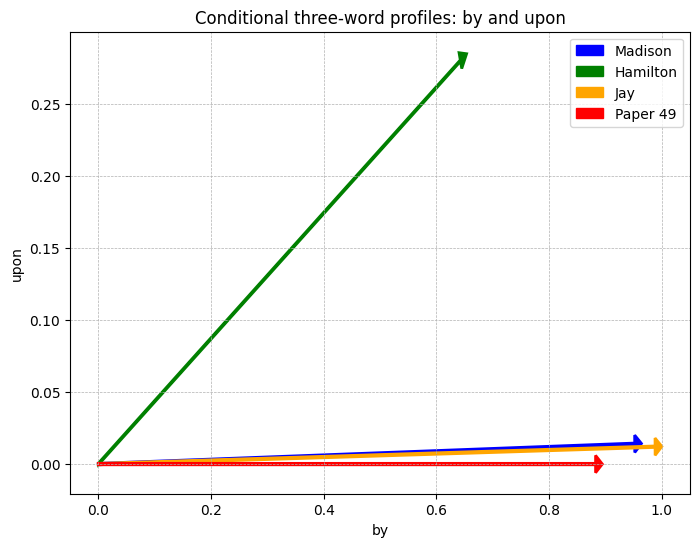

In [84]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

mu_disputed_profile = mu_disputed / mu_disputed.sum()
vector_visualizations = pd.DataFrame({
    "man": [mu_hat_madison["man_count"], mu_hat_hamilton["man_count"], mu_hat_jay["man_count"], mu_disputed_profile["man_count"]],
    "by": [mu_hat_madison["by_count"], mu_hat_hamilton["by_count"], mu_hat_jay["by_count"], mu_disputed_profile["by_count"]],
    "upon": [mu_hat_madison["upon_count"], mu_hat_hamilton["upon_count"], mu_hat_jay["upon_count"], mu_disputed_profile["upon_count"]],
    "author": ["Madison", "Hamilton", "Jay", "Paper 49"]
})

vector_visualizations_no_man = vector_visualizations.drop(columns=["man"])
colors = {"Madison": "blue", "Hamilton": "green", "Jay": "orange", "Paper 49": "red"}

plt.figure(figsize=(8, 6))
for _, row in vector_visualizations_no_man.iterrows():
    plt.arrow(0, 0, row["by"], row["upon"], head_width=0.012, head_length=0.012, linewidth=2, color=colors[row["author"]])
plt.title("Conditional three-word profiles: by and upon")
plt.xlabel("by"); plt.ylabel("upon"); plt.grid(linestyle="--", linewidth=0.5)
plt.legend(handles=[mpatches.Patch(color=color, label=author) for author, color in colors.items()])
plt.show()


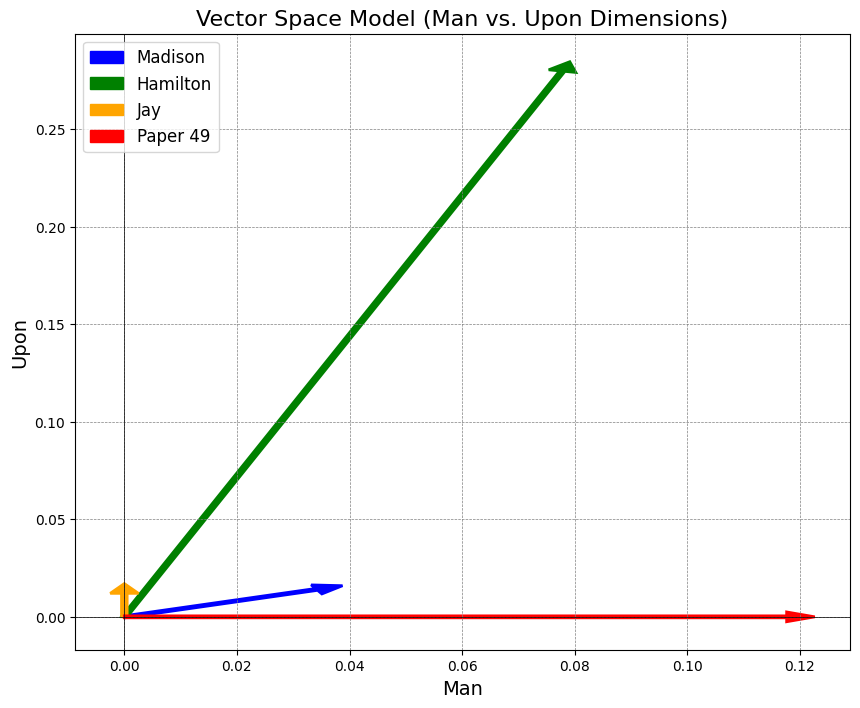

In [105]:
# Remove the "by" dimension for visualization
vector_visualizations_no_by = vector_visualizations.drop(columns=["by"])

# Visualization of vectors in 2D (man and upon dimensions) with separate colors
import matplotlib.patches as mpatches

# Set up the plot
plt.figure(figsize=(10, 8))

# Draw vector arrows with separate colors
for _, row in vector_visualizations_no_by.iterrows():
    plt.arrow(0, 0, row["man"], row["upon"],
              head_width=0.005, head_length=0.005, linewidth=2,
              color=colors[row["author"]], label=row["author"])

# Add labels and style
plt.title("Vector Space Model (Man vs. Upon Dimensions)", fontsize=16)
plt.xlabel("Man", fontsize=14)
plt.ylabel("Upon", fontsize=14)
plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)
plt.grid(color='gray', linestyle='--', linewidth=0.5)

# Add legend
handles = [mpatches.Patch(color=color, label=author) for author, color in colors.items()]
plt.legend(handles=handles, loc="upper left", fontsize=12)

# Show the plot
plt.show()


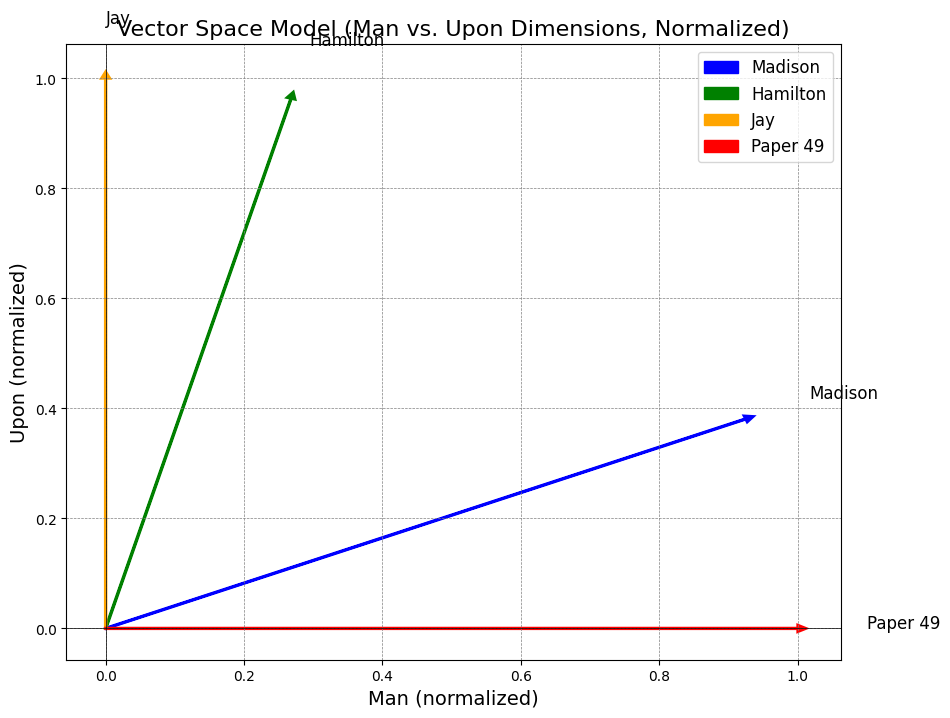

In [86]:
from sklearn.preprocessing import normalize

# Take only "man" and "upon" dimensions
X = vector_visualizations_no_by[["man", "upon"]].values

# Normalize each row vector (L2 norm = 1)
X_norm = normalize(X, norm="l2")

# Put back into a DataFrame with authors
vectors_norm = pd.DataFrame(X_norm, columns=["man", "upon"])
vectors_norm["author"] = vector_visualizations_no_by["author"]

# Visualization of normalized vectors
plt.figure(figsize=(10, 8))

for _, row in vectors_norm.iterrows():
    plt.arrow(0, 0, row["man"], row["upon"],
              head_width=0.012, head_length=0.012, linewidth=2,
              color=colors[row["author"]], label=row["author"])
    plt.text(row["man"]*1.1, row["upon"]*1.1, row["author"], fontsize=12)

# Add labels and style
plt.title("Vector Space Model (Man vs. Upon Dimensions, Normalized)", fontsize=16)
plt.xlabel("Man (normalized)", fontsize=14)
plt.ylabel("Upon (normalized)", fontsize=14)
plt.axhline(0, color="black", linewidth=0.5)
plt.axvline(0, color="black", linewidth=0.5)
plt.grid(color='gray', linestyle='--', linewidth=0.5)

# Legend
handles = [mpatches.Patch(color=color, label=author) for author, color in colors.items()]
plt.legend(handles=handles, loc="upper right", fontsize=12)

plt.show()

## Cosine similarity

For vectors $\mathbf{A}$ and $\mathbf{B}$,

$$
\cos(\theta) = \frac{\mathbf{A} \cdot \mathbf{B}}{\lVert\mathbf{A}\rVert\,\lVert\mathbf{B}\rVert}.
$$

The value describes geometric similarity. It is not a probability that two texts have the same author.


In [87]:
import numpy as np

# Define the cosine similarity function
def cosine_similarity(A, B):
    """
    Calculate the cosine similarity between two vectors A and B.
    """
    numerator = np.dot(A, B)  # Dot product
    denominator = np.sqrt(np.sum(A ** 2)) * np.sqrt(np.sum(B ** 2))  # Magnitude product
    similarity = numerator / denominator
    return similarity

# Prepare the data for analysis
vectors = vector_visualizations[["man", "by", "upon"]].to_numpy()

# Calculate similarity matrix
num_vectors = vectors.shape[0]
similarity_matrix = np.zeros((num_vectors, num_vectors))

for i in range(num_vectors):
    for j in range(num_vectors):
        similarity_matrix[i, j] = cosine_similarity(vectors[i], vectors[j])

# Add author labels to the matrix
authors = vector_visualizations["author"]
similarity_df = pd.DataFrame(similarity_matrix, index=authors, columns=authors)

# Display the similarity matrix
print("Cosine Similarity Matrix:")
print(similarity_df)


Cosine Similarity Matrix:
author     Madison  Hamilton       Jay  Paper 49
author                                          
Madison   1.000000  0.920393  0.999354  0.995220
Hamilton  0.920393  1.000000  0.916039  0.917857
Jay       0.999354  0.916039  1.000000  0.991154
Paper 49  0.995220  0.917857  0.991154  1.000000


All three profiles use only three words, so similarities can be high. The informative comparison is paper 49 against the two reference profiles, with the feature choice made explicit.


In [88]:
held_out = federalist.loc[D, ["paper_id", "author", *selected_columns]].sort_values("paper_id")
held_out


,paper_id,author,man_count,by_count,upon_count
48,49,HAMILTON OR MADISON,2,15,0
49,50,HAMILTON OR MADISON,0,11,1
50,51,HAMILTON OR MADISON,1,23,0
51,52,HAMILTON OR MADISON,0,22,0
52,53,HAMILTON OR MADISON,3,31,0
53,54,HAMILTON OR MADISON,1,26,2
54,55,HAMILTON OR MADISON,0,14,0
55,56,HAMILTON OR MADISON,0,10,0
56,57,HAMILTON OR MADISON,2,25,0
61,62,HAMILTON OR MADISON,1,28,0


# Stop words and preprocessing effects

The following frequency and TF--IDF sections are sensitivity exercises. Removing stop words changes the construct: it can remove function words such as `by`, which are central to the selected-word authorship example.


Dimensions of DTM: (85, 8614)
  word  frequency
0  the      17743
1   of      11798
2   to       7057
3  and       5080
4   in       4445


Text(0.5, 1.0, 'Word Frequency Across Federalist')

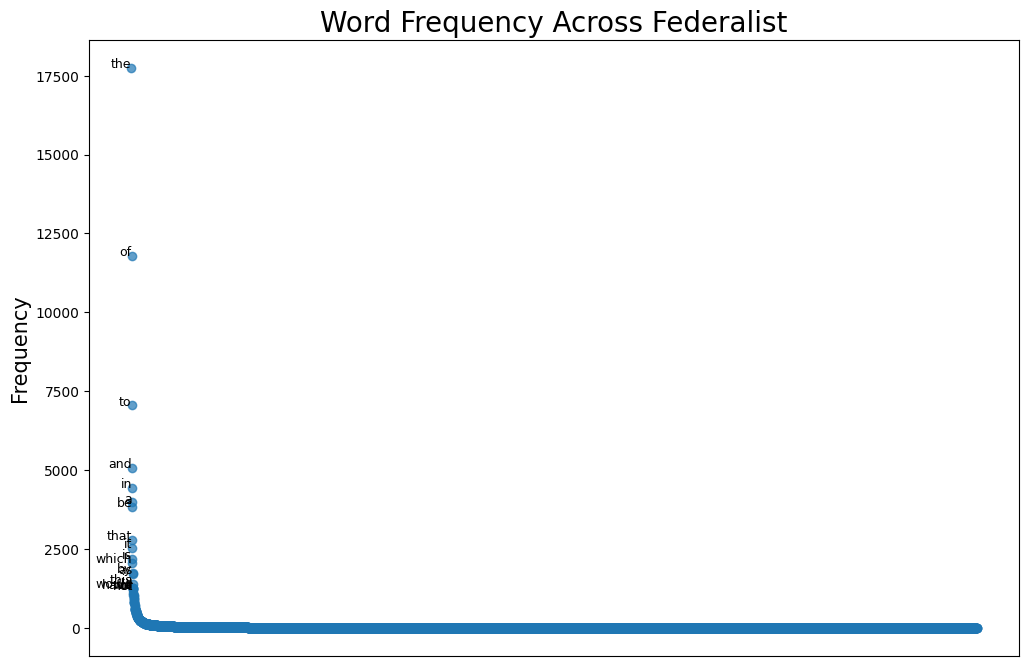

In [89]:
from sklearn.feature_extraction.text import CountVectorizer
import matplotlib.pyplot as plt
import pandas as pd

# Create a Document-Term Matrix (DTM) without removing stopwords
vectorizer = CountVectorizer(lowercase=True, token_pattern=r'\b\w+\b')  # Tokenize words
dtm_federalist = vectorizer.fit_transform(federalist['clean_text'])  # DTM as a sparse matrix

# Convert DTM to a DataFrame
dtm_df = pd.DataFrame(dtm_federalist.toarray(), columns=vectorizer.get_feature_names_out())

# Get the dimensions of the DTM
print("Dimensions of DTM:", dtm_df.shape)

# Calculate the most frequent words
most_frequent = dtm_df.sum(axis=0).sort_values(ascending=False)

# Convert to DataFrame for visualization
most_frequent_df = most_frequent.reset_index()
most_frequent_df.columns = ['word', 'frequency']

# Display the most frequent words
print(most_frequent_df.head())

# Visualization of word frequencies
from matplotlib.ticker import MaxNLocator

plt.figure(figsize=(12, 8))
plt.scatter(
    x=most_frequent_df['word'],
    y=most_frequent_df['frequency'],
    alpha=0.7
)
for i, row in most_frequent_df.iterrows():
    if row['frequency'] > 1200:
        plt.text(
            i,
            row['frequency'],
            row['word'],
            fontsize=9,
            ha='right'
        )
plt.xticks([])
plt.ylabel("Frequency", fontsize=15)
plt.title("Word Frequency Across Federalist", fontsize=20)


Zipf's Law (for many types of data studied in the physical and social sciences, the rank-frequency distribution is an inverse relation):

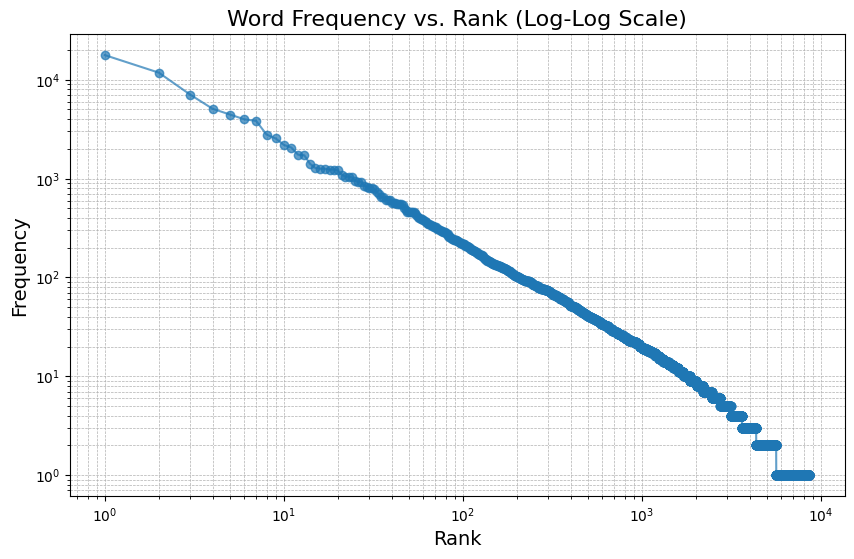

In [90]:
# Add rank to the most frequent words DataFrame
most_frequent_df['rank'] = most_frequent_df['frequency'].rank(ascending=False, method='first')

# Rank-Frequency Plot (Log-Log Scale)
plt.figure(figsize=(10, 6))

plt.plot(
    most_frequent_df['rank'],
    most_frequent_df['frequency'],
    marker='o', linestyle='-', alpha=0.7
)

# Log-log scaling
plt.xscale('log')
plt.yscale('log')

# Add labels and title
plt.xlabel("Rank", fontsize=14)
plt.ylabel("Frequency", fontsize=14)
plt.title("Word Frequency vs. Rank (Log-Log Scale)", fontsize=16)
plt.grid(visible=True, which="both", linestyle="--", linewidth=0.5)

# Display the plot
plt.show()


Dimensions of DTM: (85, 8341)
         word  frequency
0      states        851
1  government        829
2       state        787
3      people        612
4       power        606


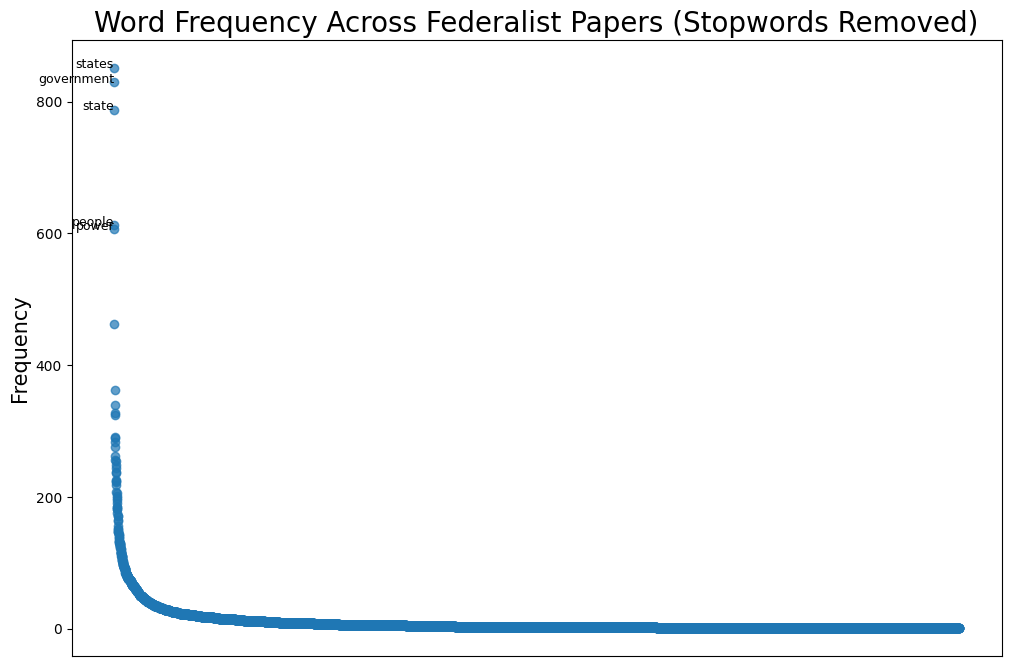

In [91]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import matplotlib.pyplot as plt

# Create a Document-Term Matrix (DTM) with stopwords removed
vectorizer = CountVectorizer(lowercase=True, token_pattern=r'\b\w+\b', stop_words='english')
dtm_federalist = vectorizer.fit_transform(federalist['clean_text'])

# Convert DTM to a DataFrame
dtm_df = pd.DataFrame(dtm_federalist.toarray(), columns=vectorizer.get_feature_names_out())

# Get the dimensions of the DTM
print("Dimensions of DTM:", dtm_df.shape)

# Calculate the most frequent words
most_frequent = dtm_df.sum(axis=0).sort_values(ascending=False)

# Convert to DataFrame for visualization
most_frequent_df = most_frequent.reset_index()
most_frequent_df.columns = ['word', 'frequency']

# Display the most frequent words
print(most_frequent_df.head())

# Visualize word frequencies (Highlight words with frequency > 500)
plt.figure(figsize=(12, 8))
plt.scatter(
    x=most_frequent_df['word'],
    y=most_frequent_df['frequency'],
    alpha=0.7
)
for i, row in most_frequent_df.iterrows():
    if row['frequency'] > 500:
        plt.text(
            i,
            row['frequency'],
            row['word'],
            fontsize=9,
            ha='right'
        )
plt.xticks([])
plt.ylabel("Frequency", fontsize=15)
plt.title("Word Frequency Across Federalist Papers (Stopwords Removed)", fontsize=20)
plt.show()


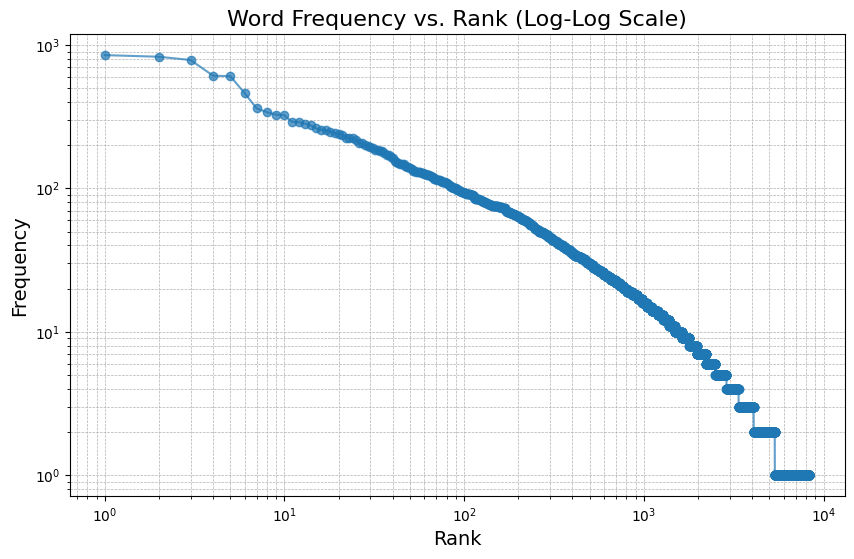

In [92]:
# Add rank to the most frequent words DataFrame
most_frequent_df['rank'] = most_frequent_df['frequency'].rank(ascending=False, method='first')

# Rank-Frequency Plot (Log-Log Scale)
plt.figure(figsize=(10, 6))

plt.plot(
    most_frequent_df['rank'],
    most_frequent_df['frequency'],
    marker='o', linestyle='-', alpha=0.7
)

# Log-log scaling
plt.xscale('log')
plt.yscale('log')

# Add labels and title
plt.xlabel("Rank", fontsize=14)
plt.ylabel("Frequency", fontsize=14)
plt.title("Word Frequency vs. Rank (Log-Log Scale)", fontsize=16)
plt.grid(visible=True, which="both", linestyle="--", linewidth=0.5)

# Display the plot
plt.show()

# TF--IDF

$$
\mathrm{tfidf}(w,d)=\mathrm{tf}(w,d)\log\frac{D}{\mathrm{df}(w)}.
$$

TF--IDF is useful for identifying terms distinctive within a collection and for retrieval. It is not itself an authorship likelihood.


In [93]:
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd

# Create a TF-IDF matrix with stopwords removed
tfidf_vectorizer = TfidfVectorizer(lowercase=True, token_pattern=r'\b\w+\b', stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(federalist['clean_text'])

# Convert TF-IDF matrix to a DataFrame
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_vectorizer.get_feature_names_out())

# Get the dimensions of the TF-IDF matrix
print("Dimensions of TF-IDF Matrix:", tfidf_df.shape)

# Calculate the most frequent terms by summing TF-IDF scores across all documents
most_frequent_tfidf = tfidf_df.sum(axis=0).sort_values(ascending=False)

# Convert to a DataFrame for visualization
most_frequent_tfidf_df = most_frequent_tfidf.reset_index()
most_frequent_tfidf_df.columns = ['word', 'tfidf_score']

# Display the most frequent terms by TF-IDF score
print(most_frequent_tfidf_df.head())


Dimensions of TF-IDF Matrix: (85, 8341)
         word  tfidf_score
0  government     7.434919
1      states     7.373848
2       state     6.833773
3      people     5.640718
4       power     5.422956


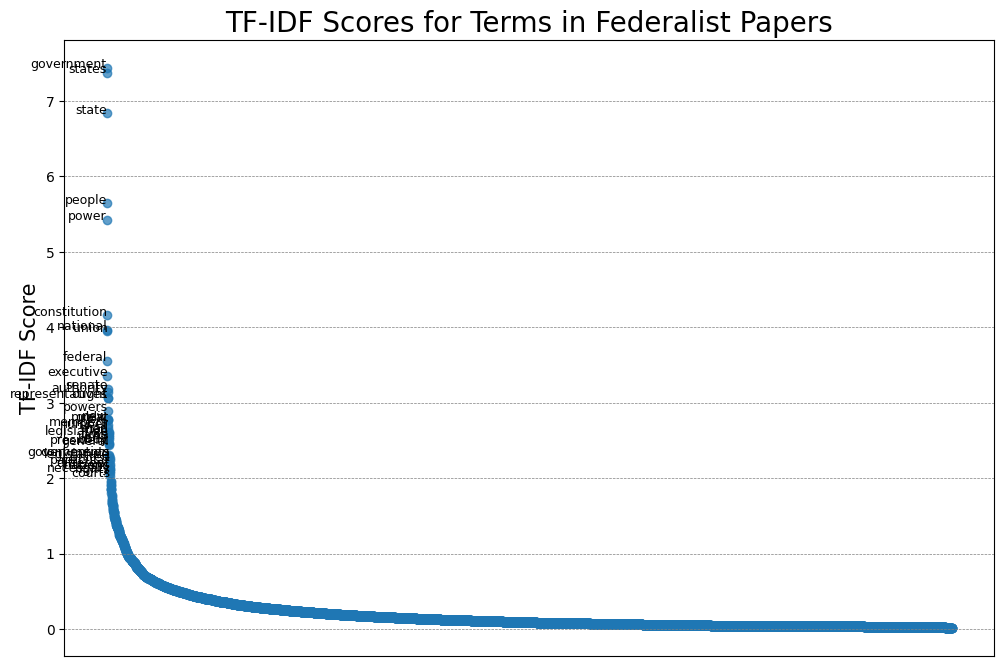

In [94]:

# Define a threshold for labeling
threshold = 2

# Create a scatter plot for TF-IDF scores
plt.figure(figsize=(12, 8))

# Scatter plot
plt.scatter(
    most_frequent_tfidf_df['word'],
    most_frequent_tfidf_df['tfidf_score'],
    alpha=0.7
)

# Add labels for terms with scores above the threshold
for i, row in most_frequent_tfidf_df.iterrows():
    if row['tfidf_score'] > threshold:
        plt.text(
            i,
            row['tfidf_score'],
            row['word'],
            fontsize=9,
            ha='right'
        )

# Customize plot appearance
plt.xticks([])
plt.ylabel("TF-IDF Score", fontsize=15)
plt.title("TF-IDF Scores for Terms in Federalist Papers", fontsize=20)
plt.grid(color='gray', linestyle='--', linewidth=0.5)

# Remove axis ticks and labels for a clean look
plt.gca().tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)
plt.show()

# Log rate ratios

For every word in the Hamilton/Madison vocabulary, the slides compare smoothed all-token rates:

$$
\log\frac{\hat p(w\mid H)}{\hat p(w\mid M)} =
\log\frac{C_{w,H}+1}{N_H+K}-\log\frac{C_{w,M}+1}{N_M+K}.
$$


In [95]:
from sklearn.feature_extraction.text import CountVectorizer
import numpy as np

# No NLTK download: clean_text already uses the shared tokenizer.
vectorizer = CountVectorizer(lowercase=False, token_pattern=r"(?u)\b\w+\b")
dtm_hm = vectorizer.fit_transform(federalist.loc[H | M, "clean_text"])
feature_names = vectorizer.get_feature_names_out()
labels_hm = federalist.loc[H | M, "author"].to_numpy()

dtm_hamilton = dtm_hm[labels_hm == "HAMILTON"].toarray().sum(axis=0)
dtm_madison = dtm_hm[labels_hm == "MADISON"].toarray().sum(axis=0)
K = len(feature_names)
rate_hamilton = (dtm_hamilton + 1) / (dtm_hamilton.sum() + K)
rate_madison = (dtm_madison + 1) / (dtm_madison.sum() + K)
log_odds_ratio = np.log(rate_hamilton) - np.log(rate_madison)

log_odds_ratio_df = pd.DataFrame({
    "word": feature_names,
    "log_odds_ratio": log_odds_ratio,
    "frequency": dtm_hamilton + dtm_madison
})
log_odds_ratio_df.sort_values("log_odds_ratio", ascending=False).head()


,word,log_odds_ratio,frequency
7588,upon,2.942209,381
4239,kind,2.771025,79
4019,intended,2.705642,36
7850,while,2.705642,36
2656,enough,2.591232,32


The quantity below is a smoothed log \emph{rate ratio}, not the difference between two Bernoulli logits. For low-frequency words the two can look similar, but they are different statistics.


In [96]:
# Inspect the extremes together with their corpus frequencies.
print("Hamilton-associated:\n", log_odds_ratio_df.nlargest(8, "log_odds_ratio"))
print("\nMadison-associated:\n", log_odds_ratio_df.nsmallest(8, "log_odds_ratio"))


Hamilton-associated:
             word  log_odds_ratio  frequency
7588        upon        2.942209        381
4239        kind        2.771025         79
4019    intended        2.705642         36
7850       while        2.705642         36
2656      enough        2.591232         32
4883  nomination        2.352821         25
5930     readily        2.313600         24
1281    commonly        2.272778         23

Madison-associated:
             word  log_odds_ratio  frequency
1960   democracy       -3.303171         10
4222    justices       -3.207861          9
623      assumed       -2.984717          7
6031      reform       -2.984717          7
3810  indirectly       -2.851186          6
7206      thirty       -2.851186          6
1343   composing       -2.777078         13
7851      whilst       -2.777078         13


Rare words can receive extreme scores. A frequency threshold is therefore a sensitivity choice, not an afterthought.


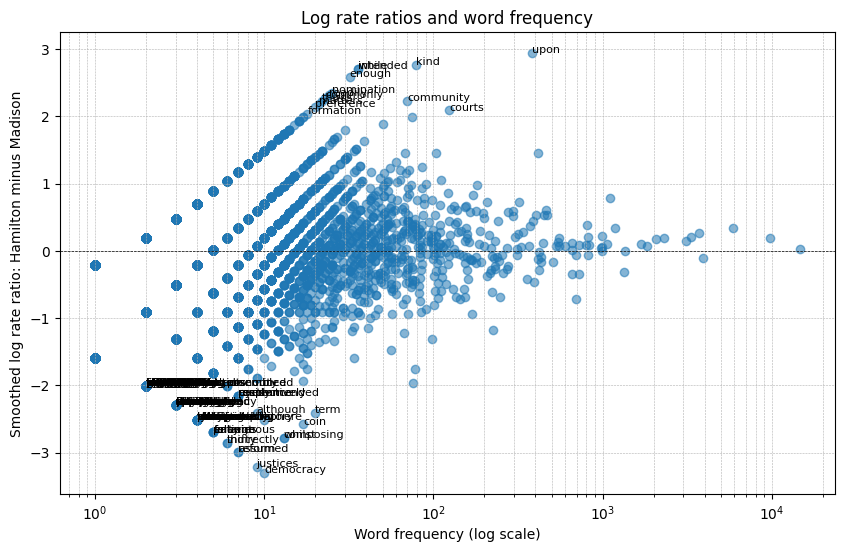

In [97]:
# Visualize log rate ratios against total frequency.
plt.figure(figsize=(10, 6))
plt.scatter(log_odds_ratio_df["frequency"], log_odds_ratio_df["log_odds_ratio"], alpha=0.55)
for _, row in log_odds_ratio_df.loc[log_odds_ratio_df["log_odds_ratio"].abs() > 2].iterrows():
    plt.text(row["frequency"], row["log_odds_ratio"], row["word"], fontsize=8)
plt.xscale("log")
plt.axhline(0, color="black", linestyle="--", linewidth=0.5)
plt.xlabel("Word frequency (log scale)")
plt.ylabel("Smoothed log rate ratio: Hamilton minus Madison")
plt.title("Log rate ratios and word frequency")
plt.grid(visible=True, which="both", linestyle="--", linewidth=0.4)
plt.show()


## Top words for Hamilton and Madison

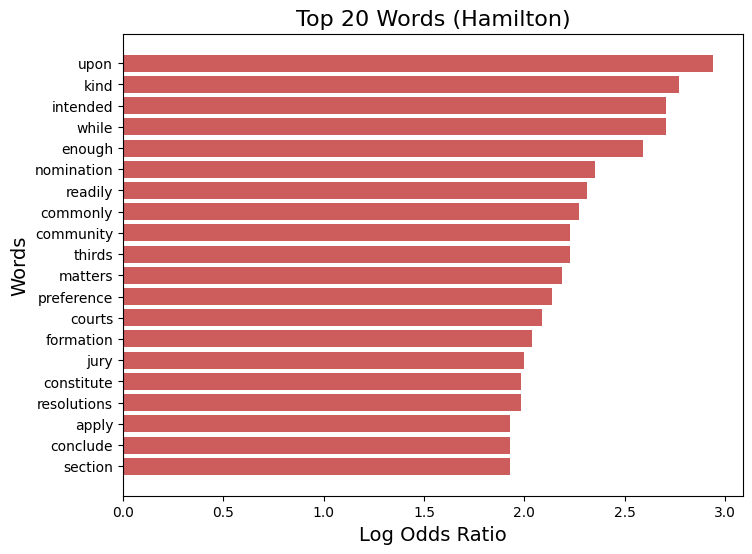

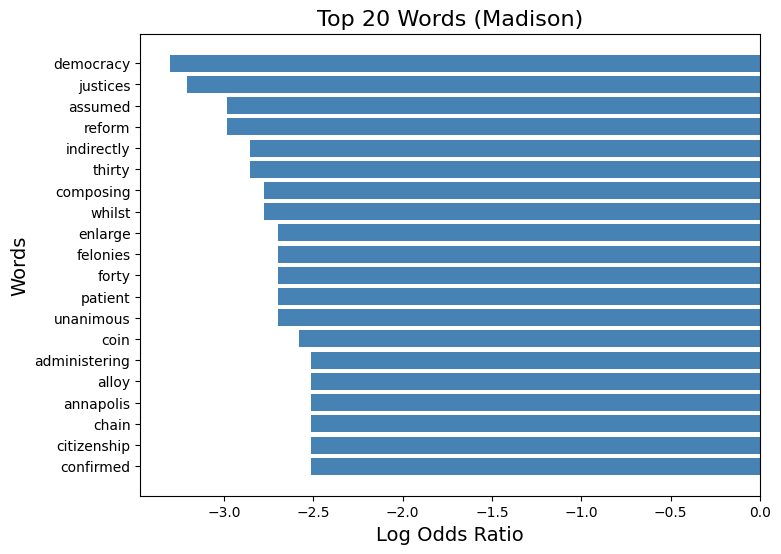

In [98]:

# Bar plots for top 20 words with highest and lowest log-odds ratio
top_hamilton = log_odds_ratio_df.nlargest(20, 'log_odds_ratio')
top_madison = log_odds_ratio_df.nsmallest(20, 'log_odds_ratio')

# Plot for Hamilton
plt.figure(figsize=(8, 6))
plt.barh(top_hamilton['word'], top_hamilton['log_odds_ratio'], color='indianred')
plt.title('Top 20 Words (Hamilton)', fontsize=16)
plt.xlabel('Log Odds Ratio', fontsize=14)
plt.ylabel('Words', fontsize=14)
plt.gca().invert_yaxis()
plt.show()

# Plot for Madison
plt.figure(figsize=(8, 6))
plt.barh(top_madison['word'], top_madison['log_odds_ratio'], color='steelblue')
plt.title('Top 20 Words (Madison)', fontsize=16)
plt.xlabel('Log Odds Ratio', fontsize=14)
plt.ylabel('Words', fontsize=14)
plt.gca().invert_yaxis()
plt.show()

# Validate the selected-word multinomial model

Leave one known Hamilton or Madison essay out of its reference profile, then predict it.


In [99]:
def loo_prediction(target_index, alpha=1):
    target_author = federalist.loc[target_index, "author"]
    target_counts = federalist.loc[target_index, selected_columns]
    h_counts = federalist.loc[H & (federalist.index != target_index), selected_columns].sum()
    m_counts = federalist.loc[M & (federalist.index != target_index), selected_columns].sum()
    ll_h = multinomial_log_likelihood(target_counts.values, smoothed_profile(h_counts, alpha).values)
    ll_m = multinomial_log_likelihood(target_counts.values, smoothed_profile(m_counts, alpha).values)
    return "HAMILTON" if ll_h > ll_m else "MADISON"

known_indices = federalist.index[H | M]
predictions = [loo_prediction(i) for i in known_indices]
truth = federalist.loc[known_indices, "author"].to_list()
correct = sum(pred == actual for pred, actual in zip(predictions, truth))
print(f"Leave-one-out accuracy: {correct}/{len(truth)} = {correct / len(truth):.1%}")
print(f"Majority baseline: {max(H.sum(), M.sum())}/{len(truth)} = {max(H.sum(), M.sum()) / len(truth):.1%}")


Leave-one-out accuracy: 64/66 = 97.0%
Majority baseline: 51/66 = 77.3%


# Visualization of conditional word usage
authors = ["Hamilton", "Madison", "Jay"]
profiles = pd.DataFrame({
    "Hamilton": mu_hat_hamilton.values,
    "Madison": mu_hat_madison.values,
    "Jay": mu_hat_jay.values,
}, index=["man", "by", "upon"])
profiles.plot(kind="bar", figsize=(9, 5))
plt.ylabel("Conditional selected-word probability")
plt.title("Conditional profiles over man, by, and upon")
plt.xticks(rotation=0)
plt.show()


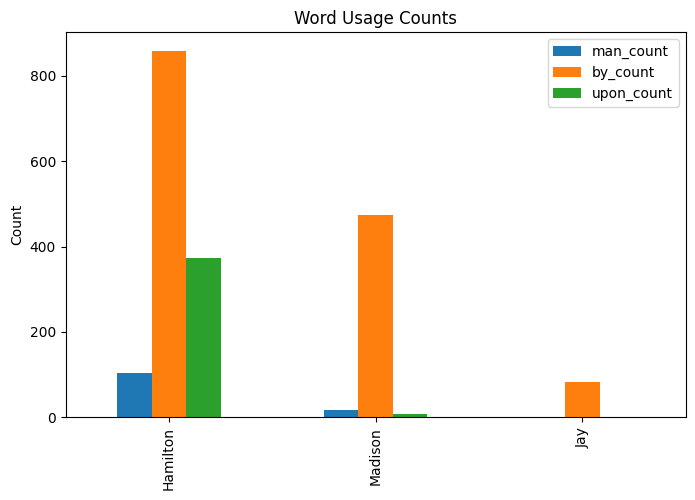

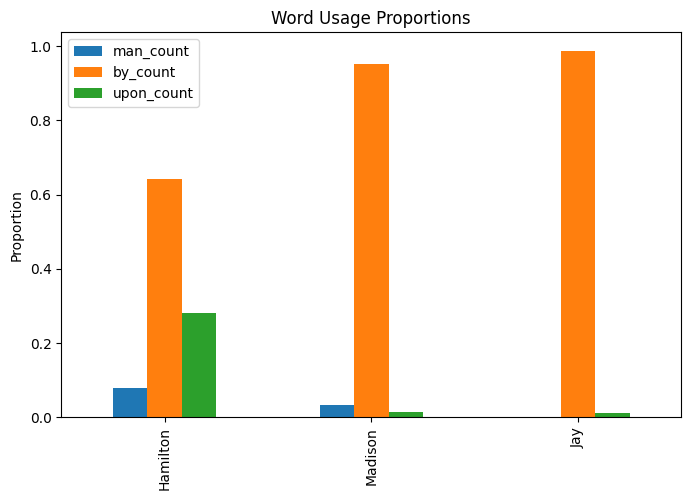

In [100]:
import matplotlib.pyplot as plt

authors = ['Hamilton','Madison','Jay']
counts = pd.DataFrame({
    'Hamilton': mu_hamilton,
    'Madison': mu_madison,
    'Jay': mu_jay
})
counts.T.plot(kind='bar', figsize=(8,5))
plt.title('Word Usage Counts')
plt.ylabel('Count')
plt.show()

# Proportions
proportions = counts.div(counts.sum(axis=0), axis=1)
proportions.T.plot(kind='bar', figsize=(8,5))
plt.title('Word Usage Proportions')
plt.ylabel('Proportion')
plt.show()

# Optional extension: multinomial Naive Bayes

This is a different model from the pooled-profile likelihood above. It learns from document-level selected-word counts. It is included as a preview of later supervised classification material, not as the main Class 3 result.


In [101]:
from sklearn.naive_bayes import MultinomialNB

X_train = federalist.loc[H | M, selected_columns]
y_train = federalist.loc[H | M, "author"]
nb = MultinomialNB(alpha=1.0, fit_prior=False).fit(X_train, y_train)
X_test = federalist.loc[federalist["paper_id"] == 49, selected_columns]
print("Naive Bayes prediction for paper 49:", nb.predict(X_test)[0])
print("Model probabilities with equal class priors:", nb.predict_proba(X_test))


Naive Bayes prediction for paper 49: MADISON
Model probabilities with equal class priors: [[0.01347333 0.98652667]]


## Exercise

- Change the selected vocabulary and rerun the conditional profile, likelihood, and validation cells.
- Compare the result after removing the shared greeting or signature.
- Explain which quantity changes: all-token rate, conditional profile, likelihood, or validation accuracy.


# Optional extension: uncertainty in word probabilities

The following Bayesian cells are not used in the slides. They show how uncertainty statements depend on a prior and the same selected-word representation.


### Word-level credible intervals

For one selected word, model its conditional probability against the other two selected words with a Beta posterior:

$$
p_{A,w}\sim\mathrm{Beta}(\alpha+c_{A,w},\;\alpha+C_A-c_{A,w}).
$$


In [102]:
rng = np.random.default_rng(0)
S = 5000
alpha = 0.5
i = 0  # man

def beta_draws(counts, index, alpha=0.5, draws=5000):
    success = alpha + counts.iloc[index]
    failure = alpha + (counts.sum() - counts.iloc[index])
    return rng.beta(success, failure, size=draws)

p_h = beta_draws(mu_hamilton, i, alpha, S)
p_m = beta_draws(mu_madison, i, alpha, S)
log_rate_ratio_draws = np.log(p_h / (1 - p_h)) - np.log(p_m / (1 - p_m))
print("Posterior mean log odds ratio for 'man':", round(log_rate_ratio_draws.mean(), 3))
print("95% credible interval:", np.quantile(log_rate_ratio_draws, [0.025, 0.975]))


Posterior mean log odds ratio for 'man': 0.875
95% credible interval: [0.3859195  1.43111724]


### Document-level posterior predictive

With equal prior odds for Hamilton and Madison, posterior draws of the two conditional word profiles produce a model-based posterior probability for paper 49. This quantifies uncertainty under the model; it does not incorporate external historical evidence.


In [103]:
from scipy.special import logsumexp

S = 5000
alpha_vec = np.ones(len(mu_hamilton)) * 0.5
x_disputed = mu_disputed.values

posterior_hamilton = []
for _ in range(S):
    p_h = rng.dirichlet(alpha_vec + mu_hamilton.values)
    p_m = rng.dirichlet(alpha_vec + mu_madison.values)
    log_h = multinomial_log_likelihood(x_disputed, p_h)
    log_m = multinomial_log_likelihood(x_disputed, p_m)
    posterior_hamilton.append(np.exp(log_h - logsumexp([log_h, log_m])))

posterior_hamilton = np.array(posterior_hamilton)
print("Posterior mean P(Hamilton | counts, equal priors):", posterior_hamilton.mean())
print("95% interval:", np.quantile(posterior_hamilton, [0.025, 0.975]))


Posterior mean P(Hamilton | counts, equal priors): 0.016032585494688674
95% interval: [0.00608713 0.03699502]


## Extension exercise

Repeat the credible-interval calculation for `by` or `upon`, then change the prior strength. Explain what remains fixed: the source labels, tokenizer, selected vocabulary, and conditional multinomial representation.
